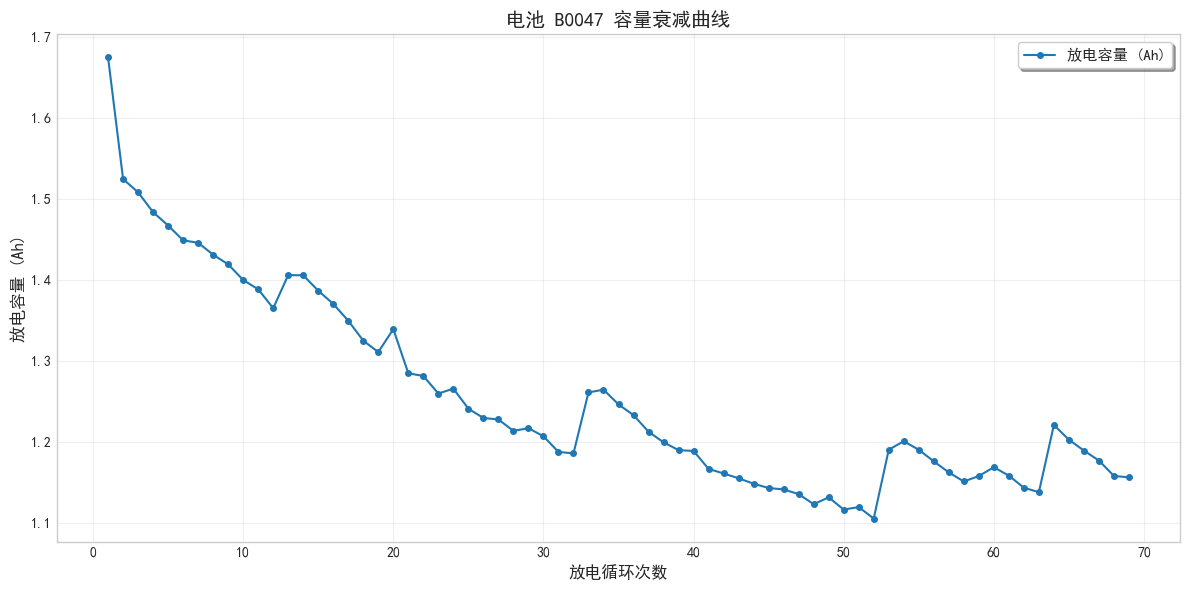

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast

# ==================== 1. 环境设置 ====================
# 设置清爽的图表风格
plt.style.use('seaborn-v0_8-whitegrid')

# 设置中文字体，防止图表中的中文显示为方块
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 用 SimHei，Mac 请改为 ['Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False    # 正常显示负号

# ==================== 2. 读取数据与清洗 ====================
# 读取官方 Metadata 数据
meta_df = pd.read_csv('./data/metadata.csv')

# 仅保留放电（discharge）数据，因为我们要计算的是放电容量衰减
discharge_df = meta_df[meta_df['type'] == 'discharge'].copy()

# 自定义清洗函数：处理含有字符串或缺失值的容量数据，确保转换为浮点数
def clean_capacity(val):
    if pd.isna(val):
        return np.nan
    try:
        if isinstance(val, str):
            val = ast.literal_eval(val) # 安全解析类似 "(2.0, 0)" 的字符串
        return float(val)
    except:
        return np.nan

# 应用清洗函数并剔除异常值（容量必须大于0）
discharge_df['cp_clean'] = discharge_df['Capacity'].apply(clean_capacity)
discharge_df = discharge_df[discharge_df['cp_clean'] > 0]

# ==================== 3. 特征工程（生成循环序号） ====================
# 按电池编号和测试记录顺序（uid）排序，确保时间轴正确
discharge_df = discharge_df.sort_values(by=['battery_id', 'uid'])

# 为每块电池生成独立的循环序号（1, 2, 3...），代表其真实的放电循环次数
discharge_df['seq'] = discharge_df.groupby('battery_id').cumcount() + 1

# ==================== 4. 提取目标数据并可视化 ====================
# 选择目标分析电池（这里选 B0047）
battery_id = 'B0047'
real_data = discharge_df[discharge_df['battery_id'] == battery_id]

fig, ax = plt.subplots(figsize=(12, 6))

# 绘制容量衰减曲线（带数据点）
ax.plot(real_data['seq'], real_data['cp_clean'], 
        marker='o', markersize=4, linewidth=1.5, color='#1f77b4', 
        label='放电容量 (Ah)')

# 图表美化与标注
ax.set_xlabel('放电循环次数', fontsize=12)
ax.set_ylabel('放电容量 (Ah)', fontsize=12)
ax.set_title(f'电池 {battery_id} 容量衰减曲线', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11, loc='upper right', frameon=True, shadow=True)

plt.tight_layout()
plt.show()